# Import the Libraries

In [113]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller,kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_percentage_error,mean_absolute_error

import warnings 
warnings.filterwarnings('ignore')

# Data Loading and Exploration

In [4]:
ticker_symbol = 'AAPL'
start_date = '2021-01-01'
end_date = '2026-01-01'

In [5]:
data = yf.download(ticker_symbol, start=start_date, end=end_date)

[*********************100%***********************]  1 of 1 completed


In [6]:
data

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2021-01-04,125.632515,129.709914,123.059867,129.622544,143301900
2021-01-05,127.185791,127.894493,124.681100,125.127679,97664900
2021-01-06,122.904518,127.224626,122.690939,123.991828,155088000
2021-01-07,127.098434,127.787716,124.127758,124.613163,109578200
2021-01-08,128.195435,128.758506,126.428554,128.564332,105158200
...,...,...,...,...,...
2025-12-24,273.066711,274.682309,271.461097,271.600701,17910600
2025-12-26,272.657806,274.622460,272.119264,273.415753,21521800


In [7]:
data.shape

(1255, 5)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1255 entries, 2021-01-04 to 2025-12-31
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   1255 non-null   float64
 1   (High, AAPL)    1255 non-null   float64
 2   (Low, AAPL)     1255 non-null   float64
 3   (Open, AAPL)    1255 non-null   float64
 4   (Volume, AAPL)  1255 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 58.8 KB


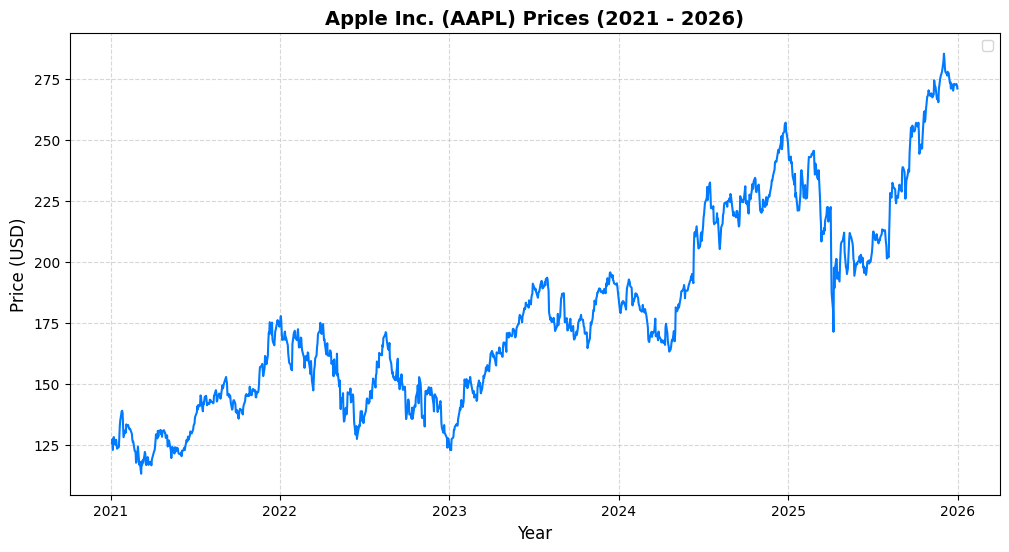

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Close'], color='#007AFF')

plt.title('Apple Inc. (AAPL) Prices (2021 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.show()                 

# Decomposition

In [11]:
decomposition_multiplicative = seasonal_decompose(data['Close'],model='multiplicative',period=252)

In [12]:
trend = decomposition_multiplicative.trend
seasonality = decomposition_multiplicative.seasonal
residual = decomposition_multiplicative.resid

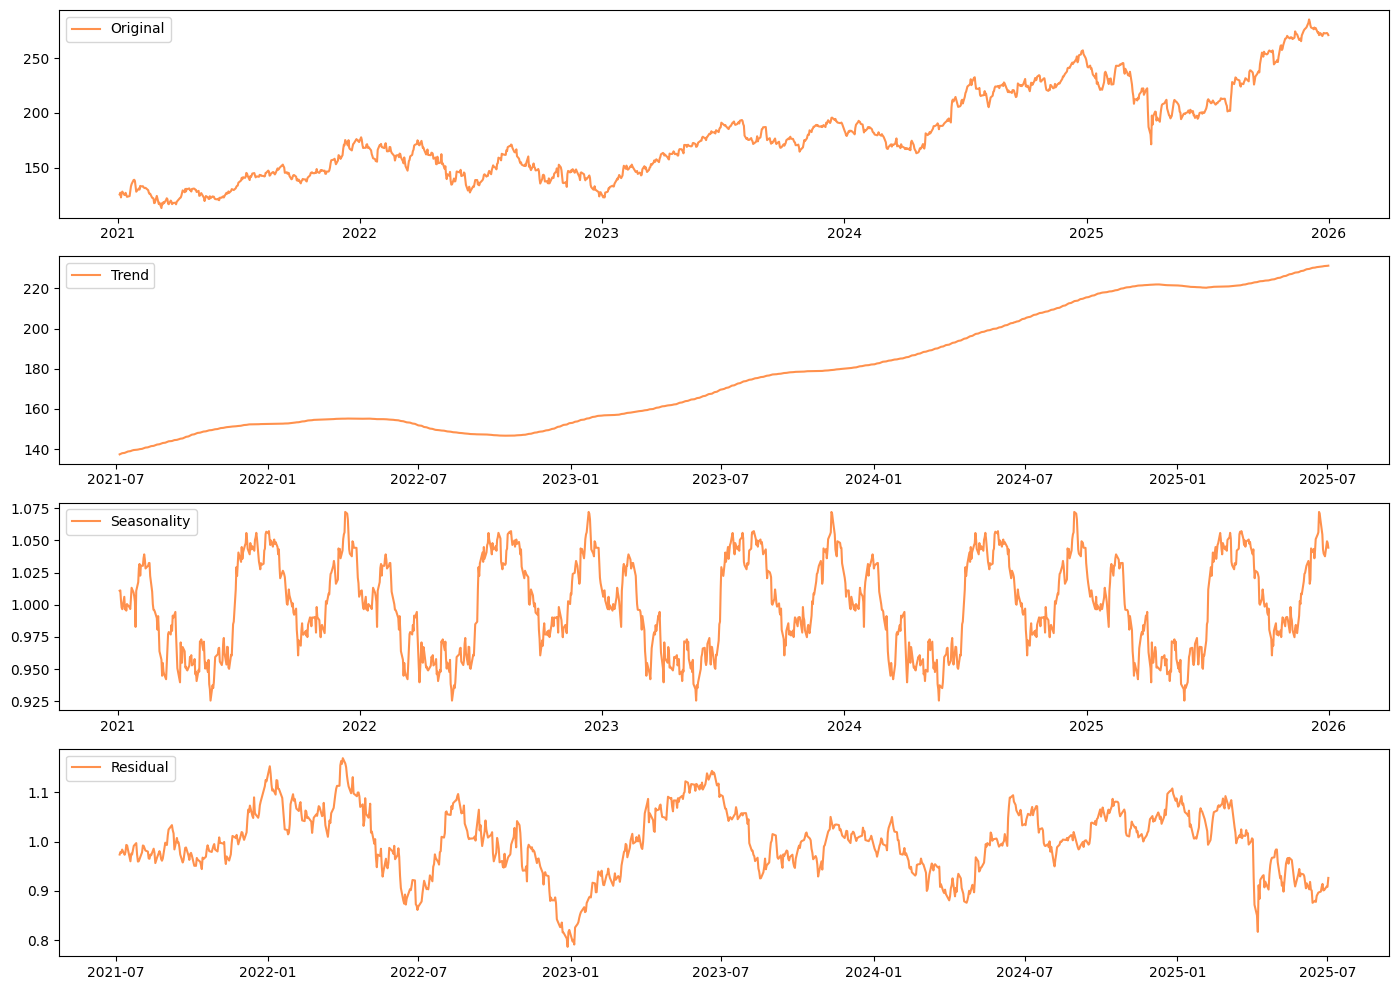

In [13]:
plt.figure(figsize=(14,10))
plt.subplot(411)
plt.plot(data['Close'],label='Original',color='#FF914D')
plt.legend(loc='upper left')
plt.subplot(412)
plt.plot(trend,label='Trend',color='#FF914D')
plt.legend(loc='upper left')
plt.subplot(413)
plt.plot(seasonality,label='Seasonality',color='#FF914D')
plt.legend(loc='upper left')
plt.subplot(414)
plt.plot(residual,label='Residual',color='#FF914D')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# Stationarity Test

## ADF Test

In [16]:
adf_result = adfuller(data['Close'])
print(f"P-Value: {adf_result[1]}")
print(f"ADF Statistic: {adf_result[0]}")
print("Critical Values")
for k,v in adf_result[4].items():
    print(f"{k}: {v}")

P-Value: 0.8228361861135007
ADF Statistic: -0.7872584291760243
Critical Values
1%: -3.4355796466416777
5%: -2.863849421064024
10%: -2.5679995625056926


## KPSS Test

In [18]:
kpss_result = kpss(data['Close'])
print(f"P-Value: {kpss_result[1]}")
print(f"ADF Statistic: {kpss_result[0]}")
print("Critical Values")
for k,v in kpss_result[3].items():
    print(f"{k}: {v}")

P-Value: 0.01
ADF Statistic: 4.993753884300873
Critical Values
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739


### From the tests, we can conclude that the series is non stationary

# Making the Data Stationary

## Differencing

In [22]:
prices = data['Close']

In [23]:
prices_diff = prices.diff()
prices_diff

Ticker,AAPL
Date,
2021-01-04,NaN
2021-01-05,1.553276
2021-01-06,-4.281273
2021-01-07,4.193916
2021-01-08,1.097000
...,...
2025-12-24,1.446045
2025-12-26,-0.408905
2025-12-29,0.359070


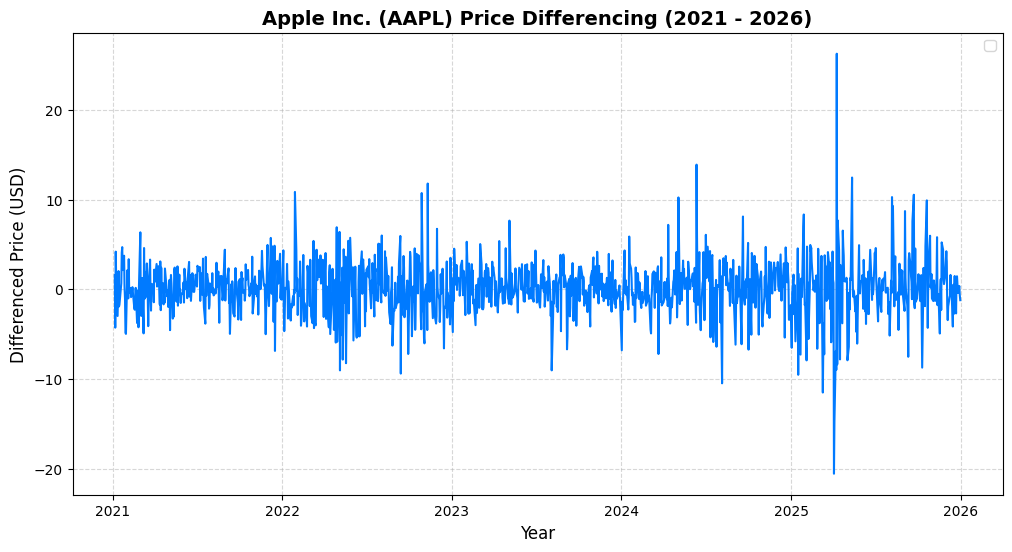

In [24]:
plt.figure(figsize=(12, 6))
plt.plot(prices_diff.index, prices_diff, color='#007AFF')

plt.title('Apple Inc. (AAPL) Price Differencing (2021 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Differenced Price (USD)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.show()   

### Data seems stationary with constant mean and constant variance. However, there is a huge spike at the start of 2025. Hence, we need to run the ADF test and KPSS test to ensure that the data is stationary

## ADF Test

In [27]:
adf_result = adfuller(prices_diff.dropna())
print(f"P-Value: {adf_result[1]}")
print(f"ADF Statistic: {adf_result[0]}")
print("Critical Values")
for k,v in adf_result[4].items():
    print(f"{k}: {v}")

P-Value: 0.0
ADF Statistic: -33.82600015742639
Critical Values
1%: -3.4355796466416777
5%: -2.863849421064024
10%: -2.5679995625056926


## KPSS Test

In [29]:
kpss_result = kpss(prices_diff.dropna())
print(f"P-Value: {kpss_result[1]}")
print(f"ADF Statistic: {kpss_result[0]}")
print("Critical Values")
for k,v in kpss_result[3].items():
    print(f"{k}: {v}")

P-Value: 0.1
ADF Statistic: 0.0625727968938367
Critical Values
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739


### From the tests, we can conclude that the series is stationary

# ACF and PACF plots

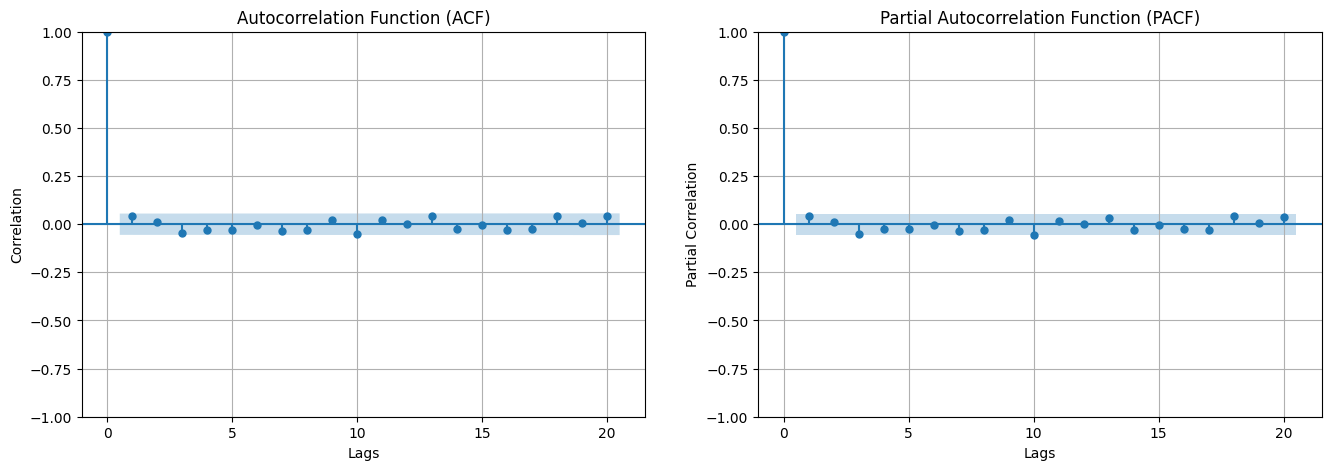

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

plot_acf(prices_diff.dropna(), lags=20, ax=axes[0], alpha=0.05)
axes[0].set_title("Autocorrelation Function (ACF)")
axes[0].set_xlabel("Lags")
axes[0].set_ylabel("Correlation")
axes[0].grid(True)

plot_pacf(prices_diff.dropna(), lags=20, ax=axes[1], alpha=0.05, method="ywm")
axes[1].set_title("Partial Autocorrelation Function (PACF)")
axes[1].set_xlabel("Lags")
axes[1].set_ylabel("Partial Correlation")
axes[1].grid(True)

## With both ACF and PACF close to 0 for all the lags and the differenced data being stationary, we conclude that the data is white noise. Let's confirm it using Ljung–Box test

In [53]:
acorr_ljungbox(prices_diff.dropna(), lags=[10, 20], return_df=True)

,lb_stat,lb_pvalue
10,14.379879,0.156359
20,24.397990,0.225439


## Since the p values are greater than 0.05, we can say that there is no significant autocorrelation and hence the differenced data is white noise and original data is random walk

# Forecasting

## ARIMA

### Multi-step Forecast

In [62]:
model = ARIMA(data['Close'], order=(0, 1, 0), trend="t")   
res = model.fit()
print(res.summary())

                               SARIMAX Results                                
Dep. Variable:                   AAPL   No. Observations:                 1255
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -3185.087
Date:                Tue, 27 Oct 2026   AIC                           6374.175
Time:                        21:00:25   BIC                           6384.443
Sample:                             0   HQIC                          6378.034
                               - 1255                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.1160      0.087      1.336      0.181      -0.054       0.286
sigma2         9.4122      0.175     53.730      0.000       9.069       9.756
Ljung-Box (L1) (Q):                   2.50   Jarque-

In [64]:
test_data = yf.download(ticker_symbol, start='2026-01-02', end='2026-10-02')

[*********************100%***********************]  1 of 1 completed


In [66]:
predict = res.get_forecast(steps=len(test_data))

In [68]:
predict

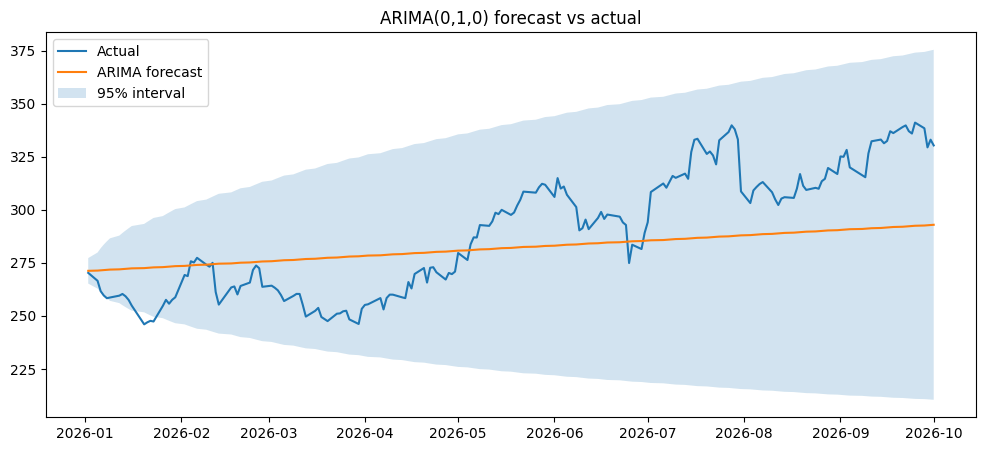

In [76]:
pred_mean = predict.predicted_mean        
pred_ci = predict.conf_int(alpha=0.05)    
pred_se = predict.se_mean 

pred_price = pred_mean.values
ci_price = pred_ci.values         
actual_price = test_data.values


pred_price = pd.Series(pred_price, index=test_data.index)
lower = pd.Series(ci_price[:, 0], index=test_data.index)
upper = pd.Series(ci_price[:, 1], index=test_data.index)

plt.figure(figsize=(12, 5))
plt.plot(test_data.index, test_data['Close'], label="Actual")
plt.plot(pred_price.index, pred_price, label="ARIMA forecast")
plt.fill_between(pred_price.index, lower, upper, alpha=0.2, label="95% interval")
plt.legend()
plt.title("ARIMA(0,1,0) forecast vs actual") 
plt.show()

In [115]:
print(mean_absolute_percentage_error(actual, pred_price) * 100)

7.057600033705014


In [119]:
print(mean_absolute_error(actual, pred_price))

20.91321187546932


### Walk-forward(rolling one-step-ahead)

In [107]:
train = data["Close"].reset_index(drop=True)            
test = test_data["Close"].reset_index(drop=True)
test.index = range(len(train), len(train) + len(test))

res = ARIMA(train, order=(0, 1, 0), trend="t").fit()
res_all = res.append(test)

start = len(train)
end = len(train) + len(test) - 1

raw = res_all.predict(start=start, end=end)
pred_walk = pd.Series(raw.values, index=test_data.index)

print(pred_walk.head())
print(len(pred_walk), len(test_data))

Date
2026-01-02    271.238025
2026-01-05    270.390338
2026-01-06    266.650531
2026-01-07    261.763812
2026-01-08    259.739306
dtype: float64
188 188


In [109]:
pred_walk.tail()

Date
2026-09-25    336.036029
2026-09-28    341.186023
2026-09-29    338.516009
2026-09-30    329.516009
2026-10-01    333.136004
dtype: float64

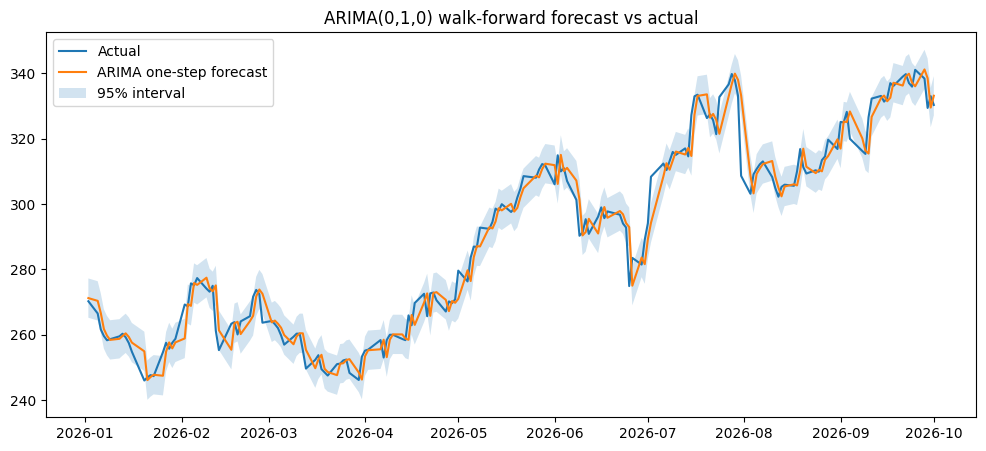

In [111]:
pred = res_all.get_prediction(start=start, end=end)

pred_walk = pd.Series(pred.predicted_mean.values, index=test_data.index)
ci = pred.conf_int(alpha=0.05)
lower = pd.Series(ci.iloc[:, 0].values, index=test_data.index)
upper = pd.Series(ci.iloc[:, 1].values, index=test_data.index)

actual = test_data["Close"]

plt.figure(figsize=(12, 5))
plt.plot(actual.index, actual, label="Actual")
plt.plot(pred_walk.index, pred_walk, label="ARIMA one-step forecast")
plt.fill_between(pred_walk.index, lower, upper, alpha=0.2, label="95% interval")
plt.legend()
plt.title("ARIMA(0,1,0) walk-forward forecast vs actual")
plt.show()

In [121]:
print(mean_absolute_percentage_error(actual, pred_walk) * 100)

1.2244236358742344


In [123]:
print(mean_absolute_error(actual, pred_walk))

3.5464971172020556
